# 🔍 Fintech AI Lab 04: Explainability, TreeSHAP & Feature Attribution
### *A Beginner-Friendly Guided Walkthrough for Students*

---

### 👋 Welcome to Lab 04!
In **Lab 01**, you mastered **Fractional Differentiation** for stationary memory with zero future leakage.
In **Lab 02**, you mastered **Cost-Sensitive Learning** to penalize catastrophic drawdown errors.
In **Lab 03**, you mastered **Probability Calibration** to transform raw scores into honest probabilities.

Now in **Lab 04**, we solve the ultimate compliance problem in algorithmic trading:
> **"Why did the AI model make this specific trade right now?"**

---

### 🧠 The Core Story: The Doctor Analogy (Global vs. Local)
Imagine a doctor diagnosing patients:
- **🌍 Global Explainability (The Textbook)**: Across 10,000 patients, which factors matter most overall? High blood pressure and cholesterol.
- **🎯 Local Explainability (Alex Today at 2:00 PM)**: Why did the doctor diagnose Alex with heart disease today? His blood pressure was fine, but his cholesterol spiked dangerously.

In trading:
- **Global**: Over the entire year, which features drove the model's overall decisions?
- **Local**: On Monday at 14:15 PM, which specific feature made the AI pull the trigger to buy SPY?

---
## 🛠️ Cell 1: Import Tools
We load our core tabular and financial libraries, plus **SHAP** (TreeSHAP):
- `numpy` & `pandas`: Data handling and table calculations.
- `matplotlib.pyplot`: Clean financial charts.
- `catboost`: Gradient Boosted Decision Tree library.
- `shap`: Game-theoretic Shapley Additive exPlanations library.

In [ ]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
import shap

# Set clean chart styling for easy reading
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print('Libraries imported successfully! SHAP and CatBoost are ready.')

---
## 📦 Cell 2: Ingest Market Feed & Causal Features from Previous Labs

To maintain **100% consistency across our curriculum**, we use the exact same **1-minute SPY dataset (780 bars, seed=42)** and calculate our **4 stationary causal features**:
1. **`FracDiff_04`**: Fractionally differenced price ($d = 0.40$), preserving trend memory with stationarity.
2. **`Causal_Vol_30m`**: Rolling 30-minute standard deviation of past price returns.
3. **`Causal_EMA_30m`**: 30-minute causal exponential moving average.
4. **`Causal_ZScore_30m`**: Standardized distance from the 30-minute rolling mean (mean-reversion indicator).

In [ ]:
# 1. Simulate 2 days of 1-minute SPY market data (780 bars) - exact same seed as Labs 01-03
np.random.seed(42)
n_minutes = 780
timestamps = [pd.Timestamp('2026-03-02 09:30:00') + pd.Timedelta(minutes=i) for i in range(n_minutes)]

# Intraday U-shaped volatility curve (busier at open/close)
minute_of_day = np.array([i % 390 for i in range(n_minutes)])
u_curve = 0.0004 + 0.0008 * ((minute_of_day - 195) / 195) ** 2
random_shocks = np.random.normal(loc=0.00002, scale=u_curve, size=n_minutes)
close_prices = np.round(505.00 * np.exp(np.cumsum(random_shocks)), 2)

df = pd.DataFrame({'Close': close_prices}, index=timestamps)

# 2. Calculate the 4 features from Lab 01
# Feature A: Fractional Differentiation (d = 0.40)
def get_frac_diff(series, d=0.40, threshold=1e-4):
    w = [1.0]
    k = 1
    while k < len(series):
        w_k = -w[-1] / k * (d - k + 1)
        if abs(w_k) < threshold: break
        w.append(w_k)
        k += 1
    w = np.array(w)[::-1]
    res = [np.dot(series.values[i - len(w) + 1 : i + 1], w) for i in range(len(w) - 1, len(series))]
    return pd.Series(res, index=series.index[len(w) - 1:])

df['FracDiff_04'] = get_frac_diff(df['Close'], d=0.40)

# Feature B: Causal Rolling Volatility (30 minutes)
df['Causal_Vol_30m'] = df['Close'].pct_change().rolling(30).std()

# Feature C: Causal Exponential Moving Average (30 minutes)
df['Causal_EMA_30m'] = df['Close'].ewm(span=30, adjust=False).mean()

# Feature D: Causal Rolling Z-Score (30 minutes)
past_mean = df['Close'].rolling(30).mean()
past_std = df['Close'].rolling(30).std()
df['Causal_ZScore_30m'] = (df['Close'] - past_mean) / past_std

# Clean empty rows from rolling warmup
df = df.dropna()
print(f'Engineered features ready! Total active rows: {len(df)}')
df.head()

---
## 🎯 Cell 3: Directional Target ($y$) & Chronological Split

Our trading task remains the forward 5-minute directional move:
- **Target Label ($y$)**:
  - **$y = 1$ (Market goes UP)**: $r_{t \to t+5} > 0$
  - **$y = 0$ (Market goes DOWN or flat)**: $r_{t \to t+5} \le 0$

We apply a strict chronological train/test split (Day 1 for training, Day 2 for testing) with zero lookahead bias.

In [ ]:
# Forward 5-minute return (looking 5 bars ahead)
horizon = 5
df['Future_Return_5m'] = df['Close'].shift(-horizon) / df['Close'] - 1.0

# Binary Directional Target: 1 for UP, 0 for DOWN
df['Target_Up'] = (df['Future_Return_5m'] > 0).astype(int)
df = df.dropna()

# Feature columns
feature_cols = ['FracDiff_04', 'Causal_Vol_30m', 'Causal_EMA_30m', 'Causal_ZScore_30m']

# Chronological cutoff point (60% train / 40% test)
split_idx = int(len(df) * 0.60)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

X_train = train_df[feature_cols]
y_train = train_df['Target_Up']

X_test = test_df[feature_cols]
y_test = test_df['Target_Up']

print(f'Train period: {train_df.index[0]} -> {train_df.index[-1]} ({len(train_df)} bars)')
print(f'Test period : {test_df.index[0]} -> {test_df.index[-1]} ({len(test_df)} bars)')

---
## 🤖 Cell 4: Train Model & Compute TreeSHAP Explainer

Now we train our CatBoost model and pass it into `shap.TreeExplainer`.

### What does `TreeExplainer` do?
- It uses an exact, high-speed algorithm to compute **Shapley values** across all decision trees in CatBoost.
- Each SHAP value represents the **marginal contribution** of that feature to pushing the model prediction away from the baseline average.

In [ ]:
# 1. Initialize and train CatBoost
model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.05,
    depth=4,
    loss_function='Logloss',
    verbose=0,
    random_seed=42
)
model.fit(X_train, y_train)

# 2. Build the TreeSHAP Explainer
explainer = shap.TreeExplainer(model)

# 3. Compute SHAP values for the test set
shap_values = explainer(X_test)

print('TreeSHAP values computed successfully!')
print(f'  - Explainer base value (expected average output): {explainer.expected_value:.4f}')
print(f'  - Shape of computed SHAP matrix: {shap_values.values.shape} (rows x features)')

---
## 🌍 Cell 5: Global Feature Attribution (Beeswarm & Importance Ranking)

Global attribution answers the big-picture question:
> **"Across the entire dataset, which features does the model rely on most, and in which direction do they push decisions?"**

### 1. Global Bar Plot (Mean |SHAP Value|)
- Ranks features by their overall average impact magnitude ($E[|\text{SHAP}|]$).
- Higher bar = more influential feature across all trades.

### 2. The SHAP Beeswarm Summary Plot (The Gold Standard)
- **Y-Axis**: Features ordered from #1 most important (top) to least important (bottom).
- **X-Axis (SHAP value)**: Impact on model decision. Points to the right ($> 0$) push toward **BUY**, points to the left ($< 0$) push toward **STAY OUT**.
- **Color (Feature Value)**: **Red = High Value**, **Blue = Low Value**.
- Each dot represents **one trading minute** from our test set!

In [ ]:
# 1. Global Feature Importance Bar Plot (Mean |SHAP Value|)
plt.figure(figsize=(10, 4))
shap.plots.bar(shap_values, show=False)
plt.title('Global Feature Importance: Mean |SHAP Value|', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Global SHAP Beeswarm Summary Plot (Directional Impact & Value Distribution)
plt.figure(figsize=(10, 5))
shap.plots.beeswarm(shap_values, show=False)
plt.title('Global SHAP Beeswarm Summary Plot (Test Set)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🎯 Cell 6: Local Trade-by-Trade Attribution (The SHAP Waterfall Plot)

Now we zoom in from **Global** to **Local** to answer the audit question:
> **"Why did the AI model execute this ONE specific trade?"**

### How to Read the Waterfall Plot:
- **Bottom ($E[f(X)]$ = -0.075)**: The base starting score before looking at this trade.
- **Red Bars ($+$)**: Features that pushed the prediction **UP** (towards BUY).
- **Blue Bars ($-$)**: Features that pulled the prediction **DOWN** (towards STAY OUT).
- **Top ($f(x)$)**: The final model score for this exact minute!

In [ ]:
# 1. Select the trade where the model was most bullish (highest total positive push)
trade_idx = int(np.argmax(shap_values.values.sum(axis=1)))
trade_time = test_df.index[trade_idx]
actual_target = test_df['Target_Up'].iloc[trade_idx]
pred_prob = model.predict_proba(X_test.iloc[[trade_idx]])[0, 1]

print('=' * 60)
print(f'🎯 LOCAL TRADE BREAKDOWN (Bar #{trade_idx}):')
print(f'  - Timestamp     : {trade_time}')
print(f'  - Predicted Prob: {pred_prob:.1%}')
print(f'  - Market Reality: {"UP (1) 🚀" if actual_target == 1 else "DOWN (0) ⚠️"}')
print('=' * 60)

# 2. Generate the SHAP Waterfall Plot for this exact trade
plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[trade_idx], show=False)
plt.title(f'SHAP Waterfall Plot: Dissecting Trade at {trade_time.strftime("%H:%M")}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🔗 Cell 7: Feature Interactions & Non-Linear Thresholds (Dependence Plots)

In financial trading, features do not act alone:
> **"What does a cheap Z-Score mean when Volatility is calm vs. when Volatility is spiking?"**

A **SHAP Dependence Plot** maps:
- **X-Axis**: The actual numeric value of Feature A.
- **Y-Axis**: The SHAP impact of Feature A on the prediction.
- **Color**: A secondary interacting feature (Feature B).

This reveals the **exact inflection points** where the model shifts from bearish ($-$) to bullish ($+$)!

<Figure size 900x500 with 0 Axes>

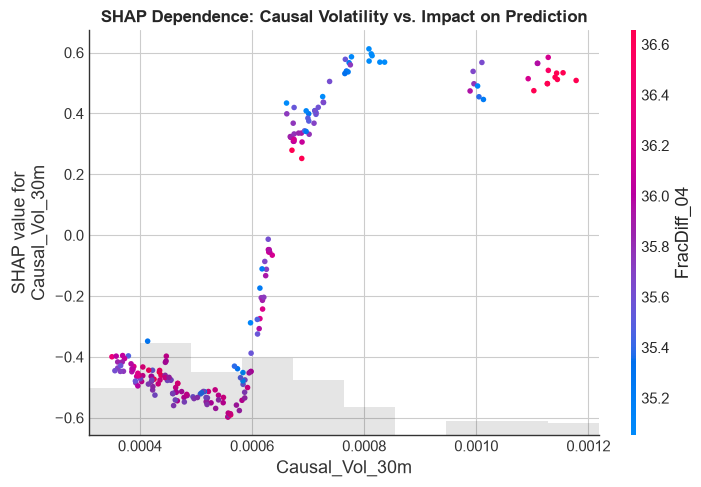

<Figure size 900x500 with 0 Axes>

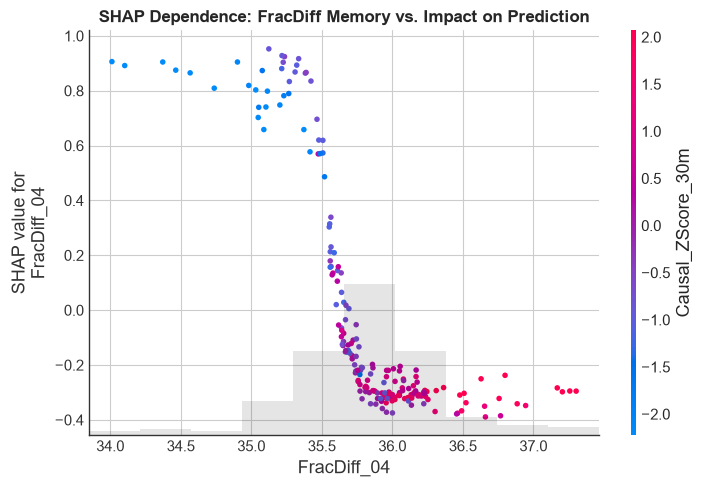

In [9]:
# 1. SHAP Dependence Plot for Causal Volatility (colored by interacting feature)
plt.figure(figsize=(9, 5))
shap.plots.scatter(shap_values[:, 'Causal_Vol_30m'], color=shap_values[:, 'FracDiff_04'], show=False)
plt.title('SHAP Dependence: Causal Volatility vs. Impact on Prediction', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. SHAP Dependence Plot for FracDiff (colored by Causal Z-Score)
plt.figure(figsize=(9, 5))
shap.plots.scatter(shap_values[:, 'FracDiff_04'], color=shap_values[:, 'Causal_ZScore_30m'], show=False)
plt.title('SHAP Dependence: FracDiff Memory vs. Impact on Prediction', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()